In [5]:
from dataclasses import dataclass

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


data = {
    'Product': ['Laptop', 'Smartphone', 'Tablet', 'Headphones', 'Smartwatch'],
    'Category': ['Electronics', 'Electronics', 'Electronics', 'Accessories', 'Electronics'],
    'Price': [1200, 800, 400, 150, 250],
}

df = pd.DataFrame(data)
print("Initial DataFrame")
print(df)
print("_" * 60)

encodec_cat = pd.get_dummies(df['Category'], prefix='Category' , dtype=int, drop_first=True)
print("Encoded DataFrame")
print(encodec_cat)


df = df.drop('Category', axis=1)
df = pd.concat([df, encodec_cat], axis=1)
print("_" * 60)
print("Final DataFrame after Encoding")
print(df)

Initial DataFrame
      Product     Category  Price
0      Laptop  Electronics   1200
1  Smartphone  Electronics    800
2      Tablet  Electronics    400
3  Headphones  Accessories    150
4  Smartwatch  Electronics    250
____________________________________________________________
Encoded DataFrame
   Category_Electronics
0                     1
1                     1
2                     1
3                     0
4                     1
____________________________________________________________
Final DataFrame after Encoding
      Product  Price  Category_Electronics
0      Laptop   1200                     1
1  Smartphone    800                     1
2      Tablet    400                     1
3  Headphones    150                     0
4  Smartwatch    250                     1


In [6]:
df_ord = pd.DataFrame({'size': ['Small', 'Medium', 'Large', 'Medium', 'Small']})
mapping = {'Small': 1, 'Medium': 2, 'Large': 3}
df_ord['size_encoded'] = df_ord['size'].map(mapping)
print("Ordinal Encoding")
print(df_ord)
print("_" * 60)

Ordinal Encoding
     size  size_encoded
0   Small             1
1  Medium             2
2   Large             3
3  Medium             2
4   Small             1
____________________________________________________________


In [7]:
df_edu = pd.DataFrame({
    'Name': ['Alice', 'Bob', 'Charlie', 'David'],
    'Education': ['High School', 'Bachelor', 'Master', 'PhD']
})

print("Original DataFrame")
print(df_edu)
print("_" * 60)

edu_mapping = {'High School': 1, 'Bachelor': 2, 'Master': 3, 'PhD': 4}
df_edu['Education_encoded'] = df_edu['Education'].map(edu_mapping)
print("DataFrame after Encoding")
print(df_edu)
print("_" * 60)




Original DataFrame
      Name    Education
0    Alice  High School
1      Bob     Bachelor
2  Charlie       Master
3    David          PhD
____________________________________________________________
DataFrame after Encoding
      Name    Education  Education_encoded
0    Alice  High School                  1
1      Bob     Bachelor                  2
2  Charlie       Master                  3
3    David          PhD                  4
____________________________________________________________


In [14]:
data = {
    'Age': [25, 30, 35, 40, 63, 28, 33, 38, 45, 50],
    'Income': [50000, 60000, 70000, 80000, 90000, 55000, 65000, 75000, 85000, 95000],
    'Satisfaction': ['Low', 'Medium', 'High', 'Medium', 'Low', 'High', 'Medium', 'Low', 'High', 'Medium'],
    'City': ['New York', 'Los Angeles', 'Chicago', 'New York', 'London', 'Los Angeles', 'London', 'San Diego', 'Dallas', 'San Jose']
}

df = pd.DataFrame(data)
print("Original DataFrame")
print(df)
print("_" * 60)

df['Age'] = (df['Age'] - df['Age'].mean()) / df['Age'].std()
df['Income'] = (df['Income'] - df['Income'].mean()) / df['Income'].std()
satisfaction_mapping = {'Low': 1, 'Medium': 2, 'High': 3}
df['Satisfaction'] = df['Satisfaction'].map(satisfaction_mapping)
df_city_encoded = pd.get_dummies(df['City'], prefix='City', dtype=int, drop_first=True)
df = pd.concat([df, df_city_encoded], axis=1)

print("DataFrame after Normalization")
print(df)


Original DataFrame
   Age  Income Satisfaction         City
0   25   50000          Low     New York
1   30   60000       Medium  Los Angeles
2   35   70000         High      Chicago
3   40   80000       Medium     New York
4   63   90000          Low       London
5   28   55000         High  Los Angeles
6   33   65000       Medium       London
7   38   75000          Low    San Diego
8   45   85000         High       Dallas
9   50   95000       Medium     San Jose
____________________________________________________________
DataFrame after Normalization
        Age    Income  Satisfaction         City  City_Dallas  City_London  \
0 -1.194394 -1.486301             1     New York            0            0   
1 -0.758484 -0.825723             2  Los Angeles            0            0   
2 -0.322574 -0.165145             3      Chicago            0            0   
3  0.113337  0.495434             2     New York            0            0   
4  2.118524  1.156012             1       London 

In [17]:
data = {
    'Employee': ['Alice', 'Bob', 'Charlie', 'David', 'Eve', 'Frank', 'Grace', 'Hannah', 'Ian', 'Jack'],
    'Department': ['HR', 'IT', 'Finance', 'IT', 'HR', 'Finance', 'IT', 'HR', 'Finance', 'IT'],
}
df = pd.DataFrame(data)
print("Original DataFrame")
print(df)
print("_" * 60)

department_counts = df['Department'].value_counts()
print("Department Counts")
print(department_counts)
print("_" * 60)

df['Department_Frequency'] = df['Department'].map(department_counts)
print("DataFrame after Frequency Encoding")
print(df)

Original DataFrame
  Employee Department
0    Alice         HR
1      Bob         IT
2  Charlie    Finance
3    David         IT
4      Eve         HR
5    Frank    Finance
6    Grace         IT
7   Hannah         HR
8      Ian    Finance
9     Jack         IT
____________________________________________________________
Department Counts
Department
IT         4
HR         3
Finance    3
Name: count, dtype: int64
____________________________________________________________
DataFrame after Frequency Encoding
  Employee Department  Department_Frequency
0    Alice         HR                     3
1      Bob         IT                     4
2  Charlie    Finance                     3
3    David         IT                     4
4      Eve         HR                     3
5    Frank    Finance                     3
6    Grace         IT                     4
7   Hannah         HR                     3
8      Ian    Finance                     3
9     Jack         IT                     4


Target DataFrame
  city  target
0   NY       1
1   LA       0
2  CHI       1
3   NY       0
4   LA       1
5  CHI       0
6   NY       1
7   LA       0
8  CHI       1
9   NY       0
____________________________________________________________
City Target Mean
city
CHI    0.666667
LA     0.333333
NY     0.500000
Name: target, dtype: float64


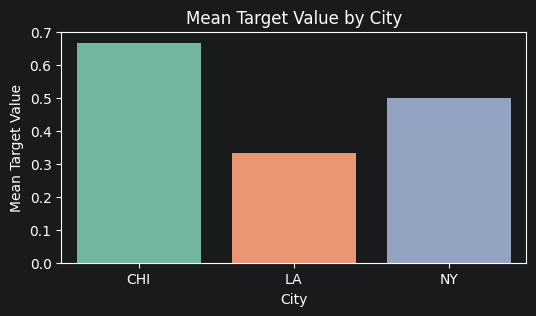

In [21]:
df_target = pd.DataFrame({
    'city': ['NY', 'LA', 'CHI', 'NY', 'LA', 'CHI', 'NY', 'LA', 'CHI', 'NY'],
    'target': [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
})
print("Target DataFrame")
print(df_target)
print("_" * 60)

city_taregt_mean = df_target.groupby('city')['target'].mean()
print("City Target Mean")
print(city_taregt_mean)

plt.figure(figsize=(6, 3))
sns.barplot(x=city_taregt_mean.index, y=city_taregt_mean.values, palette='Set2', hue=city_taregt_mean.index)
plt.title("Mean Target Value by City")
plt.xlabel("City")
plt.ylabel("Mean Target Value")
plt.show()

In [25]:
data = {
    'Order_ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    'City': ['New York', 'Los Angeles', 'Chicago', 'New York', 'Los Angeles', 'Chicago', 'New York', 'Los Angeles', 'Chicago', 'New York','London', 'San Diego', 'Dallas', 'San Jose', 'New York', 'Los Angeles', 'Chicago', 'New York', 'Los Angeles', 'Chicago'],
}

df_city = pd.DataFrame(data)
print("Original DataFrame")
print(df_city)
print("_" * 60)

counts_city = df_city['City'].value_counts()
frequency_city = counts_city[counts_city > 1].index
df_city['City_Frequency'] = df_city['City'].apply(lambda x: counts_city[x] if x in frequency_city else 0)
print("City Counts")
print(counts_city)
print("_" * 60)





Original DataFrame
    Order_ID         City
0          1     New York
1          2  Los Angeles
2          3      Chicago
3          4     New York
4          5  Los Angeles
5          6      Chicago
6          7     New York
7          8  Los Angeles
8          9      Chicago
9         10     New York
10        11       London
11        12    San Diego
12        13       Dallas
13        14     San Jose
14        15     New York
15        16  Los Angeles
16        17      Chicago
17        18     New York
18        19  Los Angeles
19        20      Chicago
____________________________________________________________
City Counts
City
New York       6
Los Angeles    5
Chicago        5
London         1
San Diego      1
Dallas         1
San Jose       1
Name: count, dtype: int64
____________________________________________________________
